# 04 — Exploratory Analysis

## Goal

This notebook explores how the amount, type, and relative intensity of ping usage relate to player performance and team outcomes.

I look at:

- the overall distribution of ping activity
- differences in ping behavior between winning and losing players
- win rate across different levels of ping activity
- excessive pinging and win rate
- differences between individual ping types
- ping behavior across player roles
- relationships between ping types and player performance
- performance differences between excessive and normal pingers
- team-level ping activity and match outcomes
- whether teams that ping more than their opponents have different win rates
- whether teams with more excessive pingers have different win rates

This notebook is exploratory. The patterns found here show associations and will be formally tested in the statistical analysis notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)

In [2]:
from pathlib import Path

FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)

In [3]:
player_df = pd.read_csv("../data/processed/player_features.csv")
team_df = pd.read_csv("../data/processed/team_features.csv")

In [4]:
player_df.head()

,match_id,game_duration,champion_id,champion_name,champion_level,champion_experience,team_id,team_position,win,kills,deaths,assists,double_kills,triple_kills,quadra_kills,penta_kills,unreal_kills,largest_killing_spree,largest_multi_kill,killing_sprees,total_damage_dealt,total_damage_dealt_to_champions,total_damage_taken,total_damage_shielded_on_teammates,physical_damage_dealt,physical_damage_dealt_to_champions,physical_damage_taken,magic_damage_dealt,magic_damage_dealt_to_champions,magic_damage_taken,true_damage_dealt,true_damage_dealt_to_champions,true_damage_taken,damage_self_mitigated,gold_earned,gold_spent,items_purchased,consumables_purchased,total_minions_killed,neutral_minions_killed,total_ally_jungle_minions_killed,total_enemy_jungle_minions_killed,vision_score,wards_placed,wards_killed,vision_wards_bought_in_game,detector_wards_placed,sight_wards_bought_in_game,dragon_kills,baron_kills,turret_kills,inhibitor_kills,nexus_kills,turret_takedowns,inhibitor_takedowns,nexus_takedowns,objectives_stolen,objectives_stolen_assists,first_blood_kill,first_blood_assist,first_tower_kill,first_tower_assist,summoner_1_id,summoner_2_id,summoner_1_casts,summoner_2_casts,spell_1_casts,spell_2_casts,spell_3_casts,spell_4_casts,total_time_spent_dead,total_time_cc_dealt,time_ccing_others,total_heal,total_heals_on_teammates,total_units_healed,effective_heal_and_shielding,largest_critical_strike,longest_time_spent_living,eligible_for_progression,game_ended_in_surrender,game_ended_in_early_surrender,team_early_surrendered,all_in_pings,assist_me_pings,basic_pings,command_pings,danger_pings,enemy_missing_pings,enemy_vision_pings,get_back_pings,hold_pings,need_vision_pings,on_my_way_pings,push_pings,retreat_pings,vision_cleared_pings,kda,kill_participation,damage_per_minute,gold_per_minute,vision_score_per_minute,solo_kills,outnumbered_kills,skillshots_hit,skillshots_dodged,wards_guarded,game_minutes,total_pings,pings_per_minute,all_in_pings_per_minute,assist_me_pings_per_minute,basic_pings_per_minute,command_pings_per_minute,danger_pings_per_minute,enemy_missing_pings_per_minute,enemy_vision_pings_per_minute,get_back_pings_per_minute,hold_pings_per_minute,need_vision_pings_per_minute,on_my_way_pings_per_minute,push_pings_per_minute,retreat_pings_per_minute,vision_cleared_pings_per_minute,all_in_pings_share,assist_me_pings_share,basic_pings_share,command_pings_share,danger_pings_share,enemy_missing_pings_share,enemy_vision_pings_share,get_back_pings_share,hold_pings_share,need_vision_pings_share,on_my_way_pings_share,push_pings_share,retreat_pings_share,vision_cleared_pings_share,excessive_pinger,ping_rate_percentile,ping_activity_level,cs,cs_per_minute,kills_per_minute,deaths_per_minute,assists_per_minute,gold_per_minute_calc,damage_per_minute_calc,vision_per_minute_calc,role_ping_percentile
0,EUW1_7447926699,1589,8,Vladimir,13,10652,100,TOP,False,2,5,1,1,0,0,0,0,2,2,1,97288,21686,25885,0,11719,1854,21032,84822,19281,4241,746,550,612,14111,7309,6950,11,0,154,0,0,0,13,7,1,0,0,0,0,0,0,0,0,0,0,0,0,0,False,False,False,False,6,4,2,2,205,7,65,6,183,76,3,17757,0,1,0,0,758,True,False,False,False,1,11,0,4,0,7,3,0,0,0,5,0,2,0,0.600000,0.142857,818.595014,275.909754,0.512124,0,1,0,8,0,26.483333,33,1.246067,0.037760,0.415356,0.0,0.151038,0.0,0.264317,0.113279,0.000000,0.0,0.000000,0.188798,0.0,0.075519,0.0,0.030303,0.333333,0.0,0.121212,0.0,0.212121,0.090909,0.000000,0.0,0.000000,0.151515,0.0,0.060606,0.0,False,0.685247,normal,154,5.814978,0.075519,0.188798,0.037760,275.984896,818.854626,0.490875,0.823973
1,EUW1_7447926699,1589,104,Graves,14,11921,100,JUNGLE,False,2,6,7,0,0,0,0,0,0,1,0,219464,10545,27528,0,164564,8517,20176,652,428,6848,54248,1599,503,20052,9711,9550,17,0,33,144,115,2,13,1,4,0,0,0,2,0,0,0,0,0,0,0,0,0,False,False,False,False,11,4,9,2,105,15,45,9,218,464,13,12611,0,1,0,375,754,True,False,False,False,0,10,0,0,0,6,0,0,0,1,3,0,0,0,1.500000,0.428571,398.065700,366.589687,0.510467,0,0,29,13,0,26.483333,20,0.755192,0.000000,0.377596,0.0,0.000000,0

In [5]:
team_df.head()

,match_id,team_id,team_win,game_minutes,team_total_pings,team_excessive_pingers,team_kills,team_deaths,team_assists,team_gold,team_damage,team_pings_per_minute,opponent_pings_per_minute,team_ping_difference
0,EUW1_6810099237,100,True,22.366667,184,2,38,14,47,54908,79181,8.226528,4.649776,3.576751
1,EUW1_6810099237,200,False,22.366667,104,1,14,38,9,39484,57954,4.649776,8.226528,-3.576751
2,EUW1_6810123481,100,True,16.400000,142,1,17,6,16,33007,42013,8.658537,6.707317,1.951220
3,EUW1_6810123481,200,False,16.400000,110,1,6,17,5,27697,28267,6.707317,8.658537,-1.951220
4,EUW1_6810162817,100,False,32.616667,334,2,38,36,57,72267,144619,10.240164,5.794584,4.445580


--------------

## 1. Overall Distribution of Ping Activity

I first look at the overall distribution of player ping rates to see what typical ping behavior looks like and how extreme the highest-pinging players are.

In [6]:
player_df["pings_per_minute"].describe(percentiles=[0.25,0.5,0.75,0.9,0.95,0.99])

count    11930.000000
mean         1.086024
std          0.925251
min          0.000000
25%          0.445054
50%          0.838542
75%          1.451272
90%          2.264795
95%          2.851629
99%          4.361668
max         10.493697
Name: pings_per_minute, dtype: float64

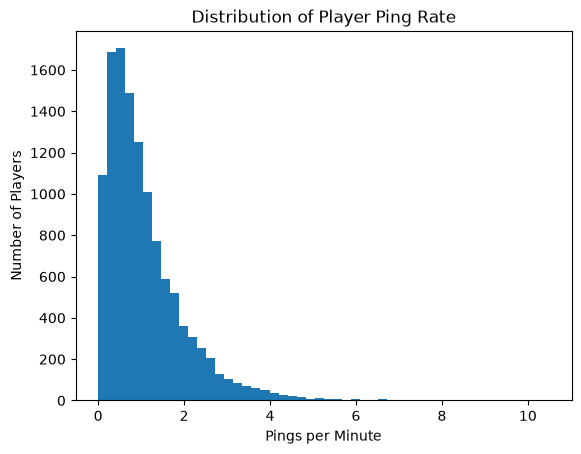

In [7]:
plt.hist(player_df["pings_per_minute"], bins=50)

plt.xlabel("Pings per Minute")
plt.ylabel("Number of Players")
plt.title("Distribution of Player Ping Rate")

plt.savefig(FIGURE_DIR / "01_ping_rate_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

Because the main question focuses on unusually high ping activity, I also look directly at the upper percentiles of the distribution.

In [8]:
player_df["pings_per_minute"].quantile(
    [0.5,0.75,0.9,0.95,0.99])

0.50    0.838542
0.75    1.451272
0.90    2.264795
0.95    2.851629
0.99    4.361668
Name: pings_per_minute, dtype: float64

----------

## 2. Ping Activity for Winners and Losers

Next, I compare ping rates between players who won and players who lost.

This gives an initial look at whether losing players tend to ping more frequently.

In [9]:
player_df.groupby("win")["pings_per_minute"].agg(
    ["count","mean","median","std"])

,count,mean,median,std
win,,,,
False,5965,1.040414,0.794521,0.895895
True,5965,1.131635,0.871863,0.951594


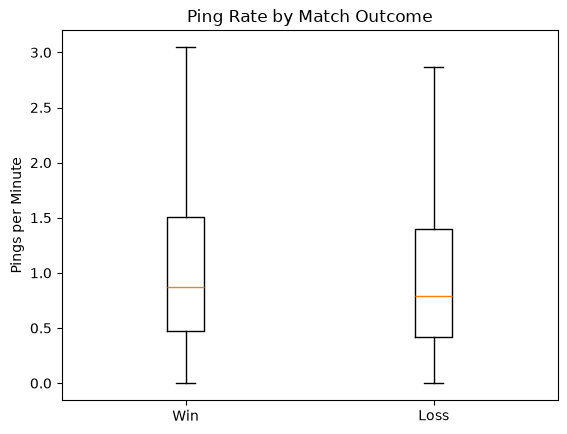

In [10]:
winner_pings = player_df.loc[player_df["win"] == True, "pings_per_minute"]

loser_pings = player_df.loc[player_df["win"] == False, "pings_per_minute"]

plt.boxplot(
    [winner_pings, loser_pings],
    tick_labels=["Win", "Loss"],
    showfliers=False #hides outliers
)

plt.ylabel("Pings per Minute")
plt.title("Ping Rate by Match Outcome")

plt.savefig(FIGURE_DIR / "02_ping_rate_by_outcome.png", dpi=300, bbox_inches="tight")

plt.show()

Outliers are hidden from the boxplot so the central distributions are easier to compare. They are still included in the dataset and later analysis.

It seems like winning teams ping slightly more than losing teams, contrary to expectations.

--------

## 3. Win Rate Across Ping Activity Levels

Although I initially expected unusually high ping activity to be associated with lower win rate, the previous comparison shows that winning players actually have a slightly higher average and median ping rate.

I next compare win rate across increasing levels of ping activity to see whether this pattern continues.

In [11]:
activity_order = ["normal", "high", "very high", "extreme"]

win_by_activity = (
    player_df.groupby("ping_activity_level", observed=True)["win"].agg(
        ["count", "mean"]).reindex(activity_order))

win_by_activity = win_by_activity.rename(columns={"mean": "win_rate"})

win_by_activity

,count,win_rate
ping_activity_level,,
normal,8947,0.488208
high,1790,0.529050
very high,596,0.523490
extreme,597,0.566164


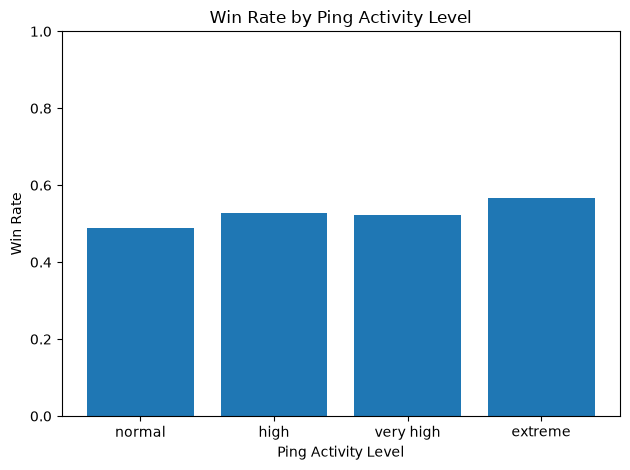

In [12]:
plt.bar(win_by_activity.index, win_by_activity["win_rate"])

plt.xlabel("Ping Activity Level")
plt.ylabel("Win Rate")
plt.title("Win Rate by Ping Activity Level")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(FIGURE_DIR / "03_win_rate_by_ping_activity.png", dpi=300, bbox_inches="tight")

plt.show()

Win rate is generally higher among the higher ping-activity groups, with the extreme group showing the highest win rate.

This is opposite to my initial expectation that unusually high ping activity would be associated with worse outcomes. Overall ping frequency may therefore reflect active communication rather than toxicity.

However, the relationship is not perfectly monotonic, and total ping frequency alone may hide differences in ping type, player role, and communication style.

--------------

## 4. Ping Types and Match Outcome

Total ping frequency may combine useful communication and potentially disruptive behavior.

I therefore compare individual ping types between winning and losing players to see whether some types show different relationships with match outcome.

In [13]:
ping_cols = [
    "all_in_pings",
    "assist_me_pings",
    "basic_pings",
    "command_pings",
    "danger_pings",
    "enemy_missing_pings",
    "enemy_vision_pings",
    "get_back_pings",
    "hold_pings",
    "need_vision_pings",
    "on_my_way_pings",
    "push_pings",
    "retreat_pings",
    "vision_cleared_pings"
]

ping_rate_cols = [f"{col}_per_minute" for col in ping_cols]

ping_type_summary = player_df.groupby("win")[ping_rate_cols].mean().T

ping_type_summary.columns = ["loss", "win"]

ping_type_summary["difference"] = ping_type_summary["win"] - ping_type_summary["loss"]

ping_type_summary.sort_values("difference")

,loss,win,difference
enemy_vision_pings_per_minute,0.113203,0.088355,-0.024849
enemy_missing_pings_per_minute,0.182293,0.163557,-0.018736
need_vision_pings_per_minute,0.010831,0.010034,-0.000796
basic_pings_per_minute,0.000000,0.000000,0.000000
hold_pings_per_minute,0.000000,0.000000,0.000000
vision_cleared_pings_per_minute,0.000000,0.000000,0.000000
danger_pings_per_minute,0.000000,0.000000,0.000000
retreat_pings_per_minute,0.080569,0.082116,0.001547
push_pings_per_minute,0.014163,0.016243,0.002080
all_in_pings_per_minute,0.017520,0.022186,0.004666


Four ping types (`basic_pings`, `danger_pings`, `hold_pings`, and `vision_cleared_pings`) contain only zero values in the cleaned dataset. Since they have no variation and cannot contribute to the analysis, they are excluded from the engineered ping features.

In [14]:
#removing unnecessary columns from player-level dataframe

player_df = pd.read_csv(
    "../data/processed/player_features.csv"
)

drop_cols = [
    "basic_pings",
    "basic_pings_per_minute",
    "basic_pings_share",

    "danger_pings",
    "danger_pings_per_minute",
    "danger_pings_share",

    "hold_pings",
    "hold_pings_per_minute",
    "hold_pings_share",

    "vision_cleared_pings",
    "vision_cleared_pings_per_minute",
    "vision_cleared_pings_share"
]

player_df = player_df.drop(
    columns=drop_cols,
    errors="ignore"
)

player_df.to_csv(
    "../data/processed/player_features.csv",
    index=False
)

print(player_df.shape)

(11930, 138)


In [15]:
ping_cols = [
    "all_in_pings",
    "assist_me_pings",
    "command_pings",
    "enemy_missing_pings",
    "enemy_vision_pings",
    "get_back_pings",
    "need_vision_pings",
    "on_my_way_pings",
    "push_pings",
    "retreat_pings"
]

ping_type_summary = ping_type_summary.drop(["basic_pings_per_minute", "danger_pings_per_minute", "hold_pings_per_minute", "vision_cleared_pings_per_minute"])
ping_type_summary

,loss,win,difference
all_in_pings_per_minute,0.017520,0.022186,0.004666
assist_me_pings_per_minute,0.105961,0.117382,0.011421
command_pings_per_minute,0.183650,0.201487,0.017837
enemy_missing_pings_per_minute,0.182293,0.163557,-0.018736
enemy_vision_pings_per_minute,0.113203,0.088355,-0.024849
get_back_pings_per_minute,0.063752,0.070760,0.007008
need_vision_pings_per_minute,0.010831,0.010034,-0.000796
on_my_way_pings_per_minute,0.268471,0.359514,0.091043
push_pings_per_minute,0.014163,0.016243,0.002080
retreat_pings_per_minute,0.080569,0.082116,0.001547


A negative difference means losers use this ping more; a positive value means winners use this ping more.

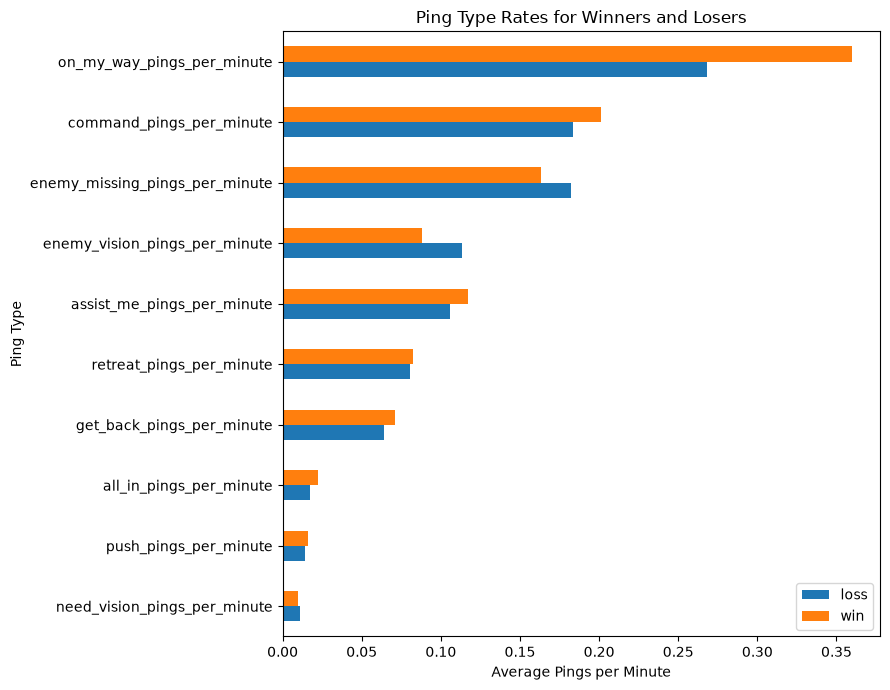

In [16]:
ping_outcome_plot = ping_type_summary[["loss", "win"]].sort_values("loss")

ax = ping_outcome_plot.plot(kind="barh", figsize=(9, 7))

ax.set_xlabel("Average Pings per Minute")
ax.set_ylabel("Ping Type")
ax.set_title("Ping Type Rates for Winners and Losers")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "04_ping_types_by_outcome.png", dpi=300, bbox_inches="tight")

plt.show()

The ping types do not all show the same relationship with match outcome.

Some ping types appear more frequently among winners, while others appear more frequently among losers. This suggests that total ping frequency may hide differences in how players use specific types of communication.

I next look at ping composition to see whether the proportion of different ping types also differs between winners and losers.

-------------

## 5. Ping Composition for Winners and Losers

Ping rate measures how frequently a player uses a ping type.

Ping share instead measures how much of a player's total ping activity comes from that specific type.

This can help distinguish between players who simply ping more overall and players whose communication is concentrated in certain ping types.

In [17]:
ping_share_cols = [f"{col}_share" for col in ping_cols]

ping_share_summary = (
    player_df.groupby("win")[ping_share_cols]
    .mean()
    .T
)

ping_share_summary.columns = [
    "loss",
    "win"
]

ping_share_summary["difference"] = (
    ping_share_summary["win"]
    - ping_share_summary["loss"]
)

ping_share_summary.sort_values(
    "difference"
)

,loss,win,difference
enemy_missing_pings_share,0.194394,0.162470,-0.031924
enemy_vision_pings_share,0.107734,0.086010,-0.021725
retreat_pings_share,0.078826,0.072049,-0.006776
get_back_pings_share,0.057590,0.055357,-0.002233
command_pings_share,0.203529,0.202140,-0.001389
need_vision_pings_share,0.008314,0.007500,-0.000814
push_pings_share,0.011452,0.011908,0.000456
all_in_pings_share,0.012540,0.014929,0.002389
assist_me_pings_share,0.088656,0.091259,0.002603
on_my_way_pings_share,0.236964,0.296379,0.059415


The differences are concentrated in only a few ping types. The largest difference in ping composition is `on_my_way_pings`, which make up a noticeably larger share of total pings among winning players. `on_my_way_pings` account for about 29.6% of winners' pings compared with 23.7% of losers' pings.

In contrast, `enemy_missing_pings` account for about 19.4% of losers' pings compared with 16.2% of winners' pings, and `enemy_vision_pings` also make up a larger share among losers.
Most other ping types show relatively small differences.

This suggests that the composition of ping usage may be more informative than total ping frequency alone.

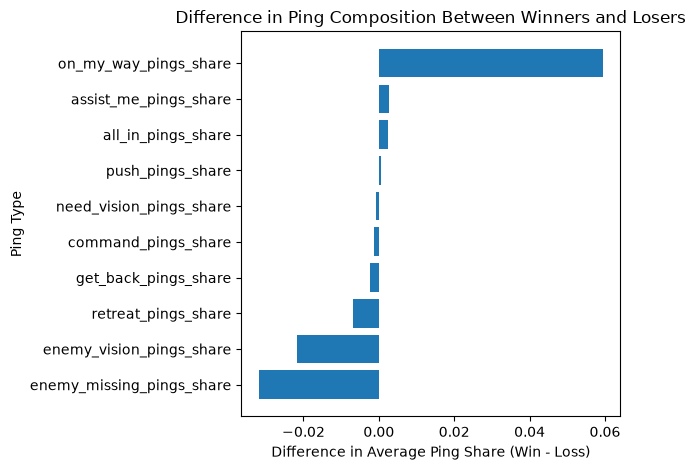

In [18]:
ping_share_difference = ping_share_summary["difference"].sort_values()

plt.barh(ping_share_difference.index, ping_share_difference.values)
plt.xlabel("Difference in Average Ping Share (Win - Loss)")
plt.ylabel("Ping Type")
plt.title("Difference in Ping Composition Between Winners and Losers")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "05_ping_share_difference_by_outcome.png", dpi=300,bbox_inches="tight")

plt.show()

Values to the right of zero indicate ping types that make up a larger share of total pings among winners.

Values to the left indicate ping types that make up a larger share among losers.

`on_my_way_pings` show the largest positive difference, while `enemy_missing_pings` and `enemy_vision_pings` show the largest negative differences.

-----------

## 6. Ping Activity by Role

Different positions may naturally use pings at different rates. I compare ping behavior across the five standard positions before interpreting high ping activity as unusual.

In [19]:
role_order = ["TOP","JUNGLE","MIDDLE","BOTTOM","UTILITY"]

role_summary = (player_df.groupby("team_position")["pings_per_minute"]
    .agg(["count","mean","median","std"]).reindex(role_order))

role_summary

,count,mean,median,std
team_position,,,,
TOP,2386,0.781755,0.605060,0.680407
JUNGLE,2386,1.491701,1.233868,1.117264
MIDDLE,2386,1.105487,0.879469,0.874307
BOTTOM,2386,0.912197,0.676556,0.795606
UTILITY,2386,1.138981,0.861750,0.939453


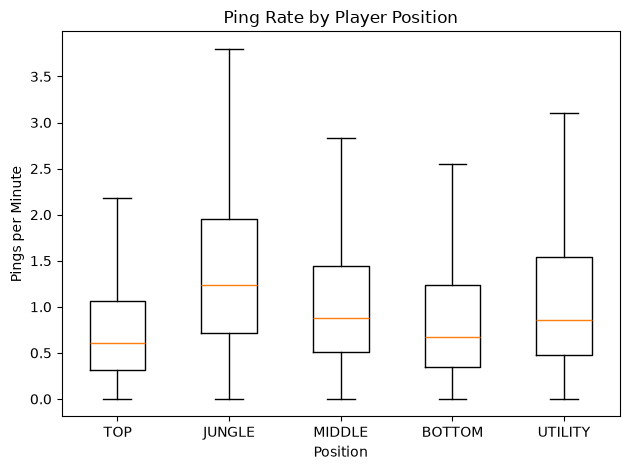

In [20]:
role_data = [player_df.loc[player_df["team_position"] == role, "pings_per_minute"] for role in role_order]

plt.boxplot(role_data, tick_labels=role_order, showfliers=False)

plt.xlabel("Position")
plt.ylabel("Pings per Minute")
plt.title("Ping Rate by Player Position")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "06_ping_rate_by_role.png", dpi=300, bbox_inches="tight")

plt.show()

Differences across positions would suggest that normal ping behavior depends partly on player role.

This is why I also created `role_ping_percentile`, which compares each player's ping activity with other players in the same position.

In [21]:
#checking excessive pinging by role

excessive_by_role = (player_df.groupby("team_position")["excessive_pinger"]
                     .mean().reindex(role_order))

excessive_by_role

team_position
TOP        0.040235
JUNGLE     0.183990
MIDDLE     0.095557
BOTTOM     0.070411
UTILITY    0.109807
Name: excessive_pinger, dtype: float64

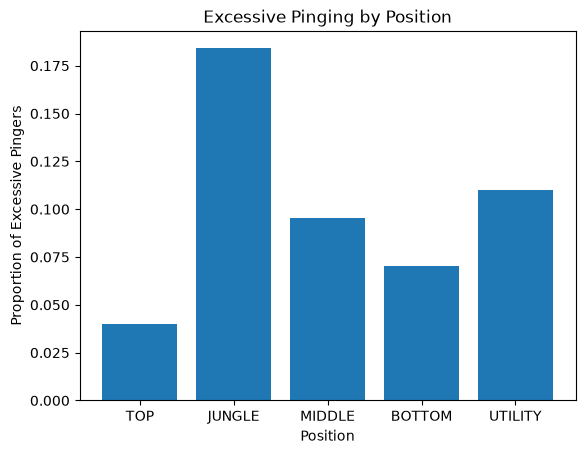

In [22]:
plt.bar(excessive_by_role.index, excessive_by_role.values)

plt.xlabel("Position")
plt.ylabel("Proportion of Excessive Pingers")
plt.title("Excessive Pinging by Position")

plt.show()

Ping activity differs substantially by position, with junglers showing the highest average ping rate and top laners the lowest.

This difference also affects the overall `excessive_pinger` label. About 18% of junglers are classified as excessive pingers using the global threshold, compared with only about 4% of top laners.

Therefore, the overall top-10% threshold partly reflects differences between roles rather than unusually high pinging within a role.

Because ping frequency differs substantially across player positions, though, the overall top-10% threshold may classify certain roles as excessive more often simply because those roles naturally ping more.

To account for this, I also define a role-adjusted excessive pinger as someone in the top 10% of ping activity among players in the same position.

In [23]:
player_df["role_excessive_pinger"] = player_df["role_ping_percentile"] >= 0.90

role_adjusted_summary = (player_df.groupby("role_excessive_pinger")["win"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "win_rate"}))

role_adjusted_summary

C:\Users\liann\AppData\Local\Temp\ipykernel_33496\3944971540.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  player_df["role_excessive_pinger"] = player_df["role_ping_percentile"] >= 0.90


,count,win_rate
role_excessive_pinger,,
False,10735,0.496134
True,1195,0.534728


In [24]:
overall_excessive_summary = (
    player_df.groupby("excessive_pinger")["win"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "win_rate"}))

print("Overall excessive definition:")
display(overall_excessive_summary)

print("Role-adjusted excessive definition:")
display(role_adjusted_summary)

Overall excessive definition:


,count,win_rate
excessive_pinger,,
False,10737,0.495017
True,1193,0.544845


Role-adjusted excessive definition:


,count,win_rate
role_excessive_pinger,,
False,10735,0.496134
True,1195,0.534728


Overall excessive pingers have a win rate of about 54.5%, compared with 49.5% for other players.

Role-adjusted excessive ping players have a win rate of about 53.5%, compared with 49.6% for other players.

The smaller difference after role adjustment suggests that player position explains part of the original relationship. However, unusually high ping activity relative to others in the same role is still associated with a higher win rate.

-------------

## 7. Overall Ping Activity and Player Performance

Win rate is only one outcome. I next examine whether overall ping frequency is associated with individual player performance.

In [25]:
performance_cols = [
    "kda",
    "cs_per_minute",
    "kills_per_minute",
    "deaths_per_minute",
    "assists_per_minute",
    "gold_per_minute_calc",
    "damage_per_minute_calc",
    "vision_per_minute_calc"
]

#we use spearman rank correlation because esports metrics rarely follow a linear line, instead league is more similar to a monotonic relationship
#spearman also uses ranks so outliers are treated normally (league data has massive outliers)

overall_performance_corr = (player_df[["pings_per_minute"] + performance_cols]
    .corr(method="spearman")["pings_per_minute"]
    .drop("pings_per_minute").sort_values())

overall_performance_corr

cs_per_minute            -0.060022
deaths_per_minute        -0.046329
damage_per_minute_calc    0.032079
gold_per_minute_calc      0.066617
kills_per_minute          0.108276
kda                       0.154136
assists_per_minute        0.161393
vision_per_minute_calc    0.185430
Name: pings_per_minute, dtype: float64

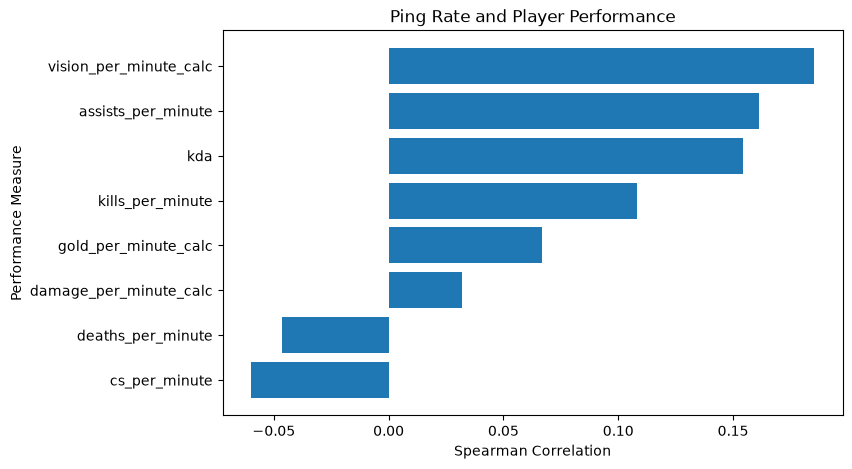

In [26]:
plt.figure(figsize=(8, 5))

plt.barh(overall_performance_corr.index, overall_performance_corr.values)

plt.xlabel("Spearman Correlation")
plt.ylabel("Performance Measure")
plt.title("Ping Rate and Player Performance")

plt.savefig(FIGURE_DIR / "07_ping_performance_correlations.png", dpi=300, bbox_inches="tight")

plt.show()

Overall ping frequency shows only weak relationships with player performance.

The strongest positive associations are with vision score per minute, assists per minute, and KDA. Higher ping activity is also weakly associated with more kills and gold per minute.

There is little relationship with damage, death rate, or CS per minute.

Overall, these results provide little evidence that higher ping frequency is associated with worse individual performance. If anything, the strongest relationships point in the opposite direction.

------

## 8. Individual Ping Types and Player Performance

Overall ping rate may hide important differences between ping types.

I calculate the Spearman correlation between each ping type and each player performance measure.

In [27]:
#note that we, again, use spearman coefficient

ping_rate_cols = [f"{col}_per_minute" for col in ping_cols]

ping_performance_corr = (player_df[ping_rate_cols + performance_cols]
    .corr(method="spearman")
    .loc[ping_rate_cols, performance_cols])

ping_performance_corr

,kda,cs_per_minute,kills_per_minute,deaths_per_minute,assists_per_minute,gold_per_minute_calc,damage_per_minute_calc,vision_per_minute_calc
all_in_pings_per_minute,0.087155,-0.005097,0.081446,-0.022445,0.083390,0.071286,0.056751,0.076635
assist_me_pings_per_minute,0.100379,-0.018656,0.116493,0.001183,0.111738,0.091776,0.079990,0.096885
command_pings_per_minute,0.106239,-0.072424,0.044864,-0.006660,0.158745,0.018859,0.043474,0.163002
enemy_missing_pings_per_minute,-0.023871,0.023632,-0.001125,0.002542,-0.029770,-0.008784,0.008219,0.018543
enemy_vision_pings_per_minute,0.026090,-0.087360,-0.023893,0.018246,0.076215,-0.051127,-0.046550,0.161361
get_back_pings_per_minute,0.087236,-0.008476,0.046251,-0.041283,0.079706,0.040893,0.028127,0.070955
need_vision_pings_per_minute,0.041589,-0.009481,0.053483,0.001070,0.052343,0.045389,0.036795,0.062318
on_my_way_pings_per_minute,0.243792,-0.025329,0.211952,-0.086235,0.200571,0.168121,0.095038,0.158910
push_pings_per_minute,0.075109,0.007940,0.051014,-0.027912,0.070435,0.052155,0.038141,0.065559
retreat_pings_per_minute,0.095039,-0.017171,0.035745,-0.077060,0.081498,0.022529,0.013361,0.104834


In [28]:
strongest_relationships = (ping_performance_corr.stack()
    .rename("correlation")
    .reset_index())

strongest_relationships.columns = ["ping_type", "performance_measure", "correlation"]

strongest_relationships["absolute_correlation"] = (
    strongest_relationships["correlation"].abs())

strongest_relationships = (strongest_relationships
    .sort_values("absolute_correlation", ascending=False))

strongest_relationships.head(20)

,ping_type,performance_measure,correlation,absolute_correlation
56,on_my_way_pings_per_minute,kda,0.243792,0.243792
58,on_my_way_pings_per_minute,kills_per_minute,0.211952,0.211952
60,on_my_way_pings_per_minute,assists_per_minute,0.200571,0.200571
61,on_my_way_pings_per_minute,gold_per_minute_calc,0.168121,0.168121
23,command_pings_per_minute,vision_per_minute_calc,0.163002,0.163002
39,enemy_vision_pings_per_minute,vision_per_minute_calc,0.161361,0.161361
63,on_my_way_pings_per_minute,vision_per_minute_calc,0.158910,0.158910
20,command_pings_per_minute,assists_per_minute,0.158745,0.158745
10,assist_me_pings_per_minute,kills_per_minute,0.116493,0.116493
12,assist_me_pings_per_minute,assists_per_minute,0.111738,0.111738


The strongest ping-performance relationships are concentrated around `on_my_way_pings`.

Higher `on_my_way_pings_per_minute` is positively associated with KDA, kills per minute, assists per minute, gold per minute, and vision score per minute.

This supports the earlier result that `on_my_way_pings` make up a larger share of total ping activity among winning players.

Rather than indicating disruptive behavior, one possible explanation is that frequent `on_my_way` pings reflect coordination, rotations, or participation in team plays. However, the direction of the relationship cannot be determined from these data. Players who are already participating in successful plays may also have more reasons to use `on_my_way` pings.

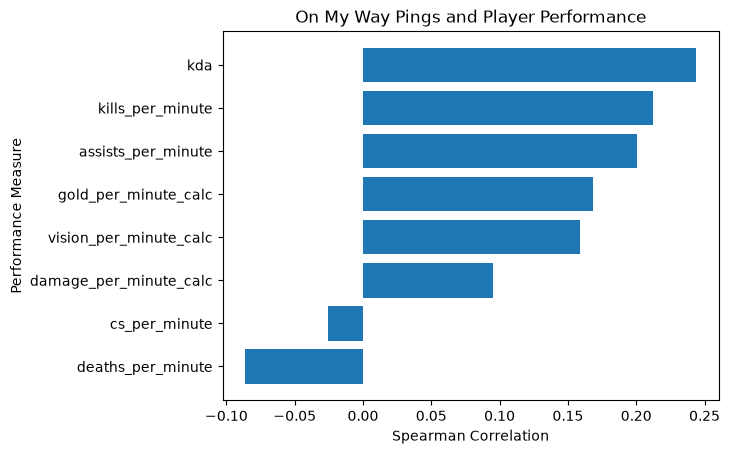

In [29]:
on_my_way_corr = (ping_performance_corr.loc["on_my_way_pings_per_minute"].sort_values())

plt.barh(on_my_way_corr.index, on_my_way_corr.values)

plt.xlabel("Spearman Correlation")
plt.ylabel("Performance Measure")
plt.title("On My Way Pings and Player Performance")

plt.savefig(FIGURE_DIR / "08_on_my_way_performance_correlations.png", dpi=300, bbox_inches="tight")

plt.show()

---

## 9. Ping Composition and Player Performance

Since ping composition showed noticeable differences between winners and losers, I also examine whether ping shares relate to individual performance.

This asks whether players who devote a larger proportion of their communication to certain ping types tend to perform differently.

In [30]:
ping_share_performance_corr = (
    player_df[ping_share_cols + performance_cols]
    .corr(method="spearman")
    .loc[ping_share_cols, performance_cols]
)

ping_share_performance_corr

,kda,cs_per_minute,kills_per_minute,deaths_per_minute,assists_per_minute,gold_per_minute_calc,damage_per_minute_calc,vision_per_minute_calc
all_in_pings_share,0.076866,-0.004186,0.077316,-0.016992,0.073914,0.068267,0.057904,0.067076
assist_me_pings_share,0.053346,0.006410,0.095513,0.018364,0.058897,0.085458,0.083383,0.034689
command_pings_share,0.006938,-0.044937,-0.028475,0.028145,0.066894,-0.030221,0.025858,0.051460
enemy_missing_pings_share,-0.131603,0.065502,-0.080755,0.030197,-0.143797,-0.059079,-0.016703,-0.101855
enemy_vision_pings_share,-0.011516,-0.082992,-0.056812,0.029852,0.042762,-0.074619,-0.055954,0.126620
get_back_pings_share,0.062761,-0.001580,0.025481,-0.035486,0.056622,0.026842,0.021413,0.045572
need_vision_pings_share,0.033827,-0.007391,0.049284,0.004211,0.044930,0.042441,0.038014,0.054473
on_my_way_pings_share,0.212733,0.024140,0.214946,-0.083682,0.138294,0.188622,0.111812,0.050837
push_pings_share,0.069020,0.011487,0.049274,-0.026134,0.062672,0.052491,0.040861,0.057754
retreat_pings_share,0.060804,-0.005210,0.008414,-0.068895,0.047601,0.006306,0.008089,0.068310


In [31]:
strongest_share_relationships = (ping_share_performance_corr
    .stack().rename("correlation").reset_index())

strongest_share_relationships.columns = ["ping_share", "performance_measure", "correlation"]

strongest_share_relationships["absolute_correlation"] = (
    strongest_share_relationships["correlation"].abs())

strongest_share_relationships = (strongest_share_relationships
    .sort_values("absolute_correlation", ascending=False))

strongest_share_relationships.head(20)

,ping_share,performance_measure,correlation,absolute_correlation
58,on_my_way_pings_share,kills_per_minute,0.214946,0.214946
56,on_my_way_pings_share,kda,0.212733,0.212733
61,on_my_way_pings_share,gold_per_minute_calc,0.188622,0.188622
28,enemy_missing_pings_share,assists_per_minute,-0.143797,0.143797
60,on_my_way_pings_share,assists_per_minute,0.138294,0.138294
24,enemy_missing_pings_share,kda,-0.131603,0.131603
39,enemy_vision_pings_share,vision_per_minute_calc,0.126620,0.126620
62,on_my_way_pings_share,damage_per_minute_calc,0.111812,0.111812
31,enemy_missing_pings_share,vision_per_minute_calc,-0.101855,0.101855
10,assist_me_pings_share,kills_per_minute,0.095513,0.095513


Because ping shares are compositional, these variables are not independent of one another. A larger share of one ping type necessarily means a smaller combined share of other ping types.

These results are therefore useful for exploration but should be interpreted carefully.

--------------

## 10. Performance of Excessive Pingers

I compare the performance of players in the top 10% of ping frequency with everyone else.

Since many performance variables are skewed, I compare medians.

In [45]:
performance_by_excessive = (
    player_df.groupby("excessive_pinger")[performance_cols].median().T)

performance_by_excessive.columns = ["not_excessive", "excessive"]

performance_by_excessive["difference"] = (
    performance_by_excessive["excessive"] - performance_by_excessive["not_excessive"])

performance_by_excessive

,not_excessive,excessive,difference
kda,2.250000,2.833333,0.583333
cs_per_minute,6.504630,6.273556,-0.231073
kills_per_minute,0.171184,0.211392,0.040208
deaths_per_minute,0.198020,0.188976,-0.009043
assists_per_minute,0.226950,0.282021,0.055071
gold_per_minute_calc,396.739266,409.708249,12.968984
damage_per_minute_calc,677.334059,701.406593,24.072535
vision_per_minute_calc,0.636605,0.746562,0.109957


Players classified as excessive pingers do not appear to perform worse overall.

They have higher median KDA, kills per minute, assists per minute, gold per minute, damage per minute, and vision score per minute, along with a slightly lower death rate.

The main exception is CS per minute, which is lower among excessive pingers. This may partly reflect the role imbalance found earlier, since roles differ substantially in both ping activity and farming behavior.

This reinforces the importance of controlling for player position in later statistical analysis.

-----------

## 11. Team-Level Ping Activity and Match Outcome

The previous sections treat each player as one observation.

However, all five players on the same team share the same win/loss outcome.

For team-level questions, I therefore use `team_df`, where one row represents one team in one match.

In [46]:
#stats of team_pings_per_minute

team_df.groupby("team_win")["team_pings_per_minute"].agg(["count","mean","median","std"])

,count,mean,median,std
team_win,,,,
False,1193,5.202068,4.896627,2.114089
True,1193,5.658176,5.351044,2.183781


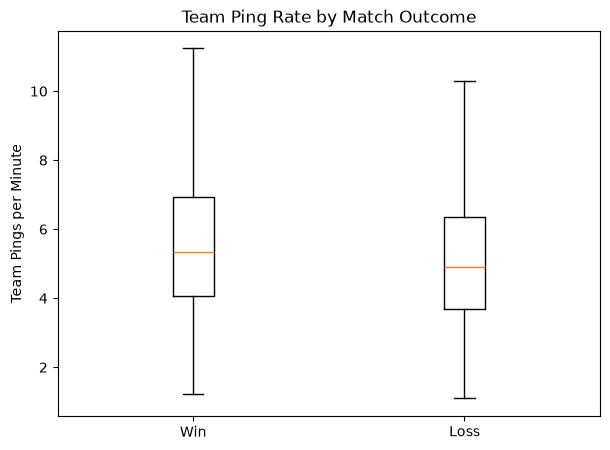

In [47]:
winning_team_pings = team_df.loc[
    team_df["team_win"] == True,
    "team_pings_per_minute"]

losing_team_pings = team_df.loc[
    team_df["team_win"] == False,
    "team_pings_per_minute"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [winning_team_pings, losing_team_pings],
    tick_labels=["Win", "Loss"],
    showfliers=False)

plt.ylabel("Team Pings per Minute")
plt.title("Team Ping Rate by Match Outcome")


plt.savefig(FIGURE_DIR / "08_team_ping_rate_by_outcome.png", dpi=300, bbox_inches="tight")

plt.show()

Using one row per team gives a cleaner comparison for match outcome than treating the five players on the same team as independent win/loss observations.

-------------

## 12. Ping Activity Relative to the Opponent

Absolute ping rate may be influenced by characteristics of the match.

I therefore compare each team's ping rate directly with the opposing team in the same game.

`team_ping_difference` is: **team pings per minute - opponent pings per minute**

A positive value means the team pinged more than its opponent.

In [38]:
team_df.groupby("team_win")["team_ping_difference"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
team_win,,,,
False,1193,-0.456108,-0.436893,2.851506
True,1193,0.456108,0.436893,2.851506


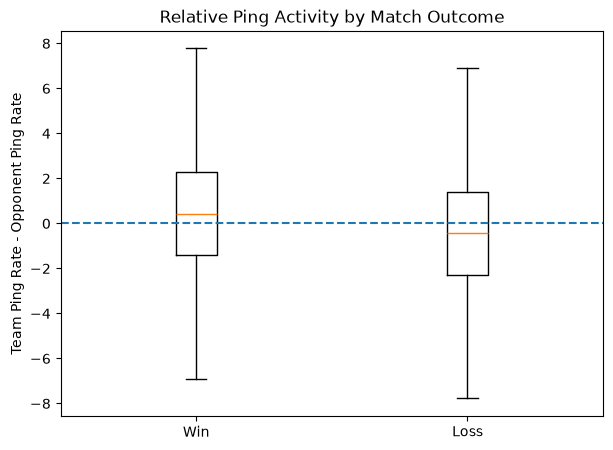

In [48]:
win_ping_difference = team_df.loc[team_df["team_win"] == True, "team_ping_difference"]

loss_ping_difference = team_df.loc[team_df["team_win"] == False, "team_ping_difference"]

plt.figure(figsize=(7, 5))

plt.boxplot([win_ping_difference,loss_ping_difference], tick_labels=["Win", "Loss"], showfliers=False)

plt.axhline(0,linestyle="--")
plt.ylabel("Team Ping Rate - Opponent Ping Rate")
plt.title("Relative Ping Activity by Match Outcome")

plt.savefig(FIGURE_DIR / "09_team_ping_difference_by_outcome.png", dpi=300, bbox_inches="tight")

plt.show()

This within-match comparison is useful because both teams experience the same match duration and general game environment.

Winning teams ping more than losing teams at the team level.

The within-match comparison shows the same pattern: winning teams average about 0.46 more pings per minute than their opponents, while losing teams average about 0.46 fewer.

This strengthens the descriptive evidence that higher overall ping activity is associated with winning rather than losing in this dataset.

-------

## 13. Win Rate Relative to Opponent Ping Activity

I make the team comparison easier to interpret by classifying each team as having pinged less, the same amount, or more than its opponent.

In [49]:
team_df["relative_ping_level"] = np.select(
    [team_df["team_ping_difference"] < 0, team_df["team_ping_difference"] > 0],
    ["pinged less", "pinged more"],
    default="same")

In [50]:
relative_ping_summary = (team_df.groupby("relative_ping_level")["team_win"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "win_rate"}))

relative_ping_summary

,count,win_rate
relative_ping_level,,
pinged less,1190,0.444538
pinged more,1190,0.555462
same,6,0.500000


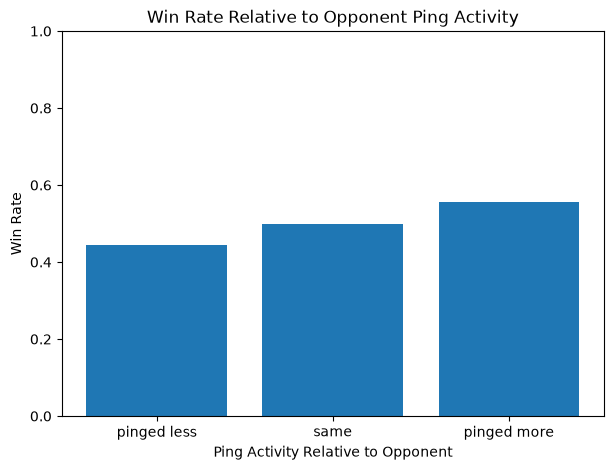

In [53]:
relative_order = [group for group in ["pinged less", "same", "pinged more"]
    if group in ["pinged less", "same", "pinged more"]]

plt.figure(figsize=(7, 5))

plt.bar(relative_order, relative_ping_summary.loc[relative_order, "win_rate"])

plt.xlabel("Ping Activity Relative to Opponent")
plt.ylabel("Win Rate")
plt.title("Win Rate Relative to Opponent Ping Activity")
plt.ylim(0, 1)

plt.show()

----

## 14. Number of Excessive Pingers on a Team

A team's ping rate could be caused by one unusually active player rather than the entire team.

I therefore examine whether win rate changes depending on how many players on the team are classified as excessive pingers.

In [54]:
excessive_team_summary = (team_df.groupby("team_excessive_pingers")["team_win"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "win_rate"}))

excessive_team_summary

,count,win_rate
team_excessive_pingers,,
0,1433,0.472435
1,745,0.534228
2,178,0.573034
3,28,0.571429
4,2,0.000000


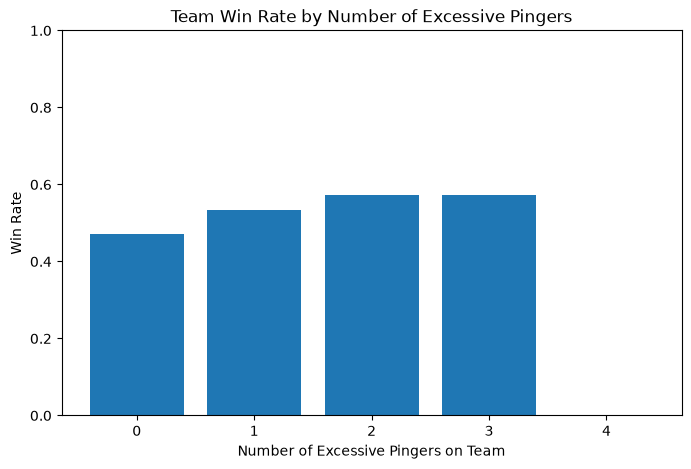

In [55]:
plt.figure(figsize=(8, 5))

plt.bar(excessive_team_summary.index, excessive_team_summary["win_rate"])

plt.xlabel("Number of Excessive Pingers on Team")
plt.ylabel("Win Rate")
plt.title("Team Win Rate by Number of Excessive Pingers")

plt.ylim(0, 1)

plt.show()

----

## 15. Conclusions

The exploratory results do not support my initial expectation that higher overall ping frequency would be associated with worse outcomes. Instead, higher ping activity is descriptively associated with higher win rates and several positive performance measures.

The results also suggest that ping type, ping composition, and player role may be more informative than total ping frequency alone. In particular, `on_my_way` pings make up a larger share of ping activity among winners, while `enemy_missing` and `enemy_vision` pings make up larger shares among losers. Ping frequency also differs substantially across roles, showing the importance of accounting for player position when defining unusually high ping activity.

Overall, these patterns suggest that high ping frequency alone may not be a good proxy for toxicity. However, the exploratory results are descriptive and do not establish whether these differences are statistically significant or whether they remain after accounting for other factors.

The next notebook uses statistical tests and regression models to evaluate these relationships more formally.